# Avoiding default legends

## Moving the legend to inside the chart

In this notebook, I explore data visualizations that eliminate the default legend from a chart. Alternatives to the standard legend are accomplished by directly labeling the visualizations or by faceting to create sub-panels for each category.

This focuses on moving a line chart's legend from the default left-hand side of the chart to inside the chart's panel. Making it more accessible to the audience. 

In [1]:
from datetime import date
import polars as pl
from plotnine import *

## CPI Index data from the Federal Reserve Bank of St. Louis 

(FRED == Federal Reserve Economic Data)

I'm using data pulled online from FRED. Common categories were chosen for this example. Food, Housing, Apparel, and Medical Care data were retrieved using the "unofficial" API; this allowed me to directly read the CSV files into a data frame for analysis and plotting. 

The raw data was organized as a "long" Polars data frame.

In [2]:
# 1. Define the categories and their FRED IDs
categories = {
    "Food": "CPIFABNS",
    "Housing": "CPIHOSNS",
    "Apparel": "CPIAPPNS",
    # "Transportation": "CPITRNNS", # Exclude as the variation is large.
    "Medical Care": "CPIMEDNS"
}

# 2. Read each series and stack into one long DataFrame
long_df = pl.concat(
    pl.read_csv(
        f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}",
        null_values=["."],
    ).select(
        pl.col("observation_date").str.to_date(),
        pl.col(series_id).cast(pl.Float64).alias("value"),
        pl.lit(name).alias("category"),
    )
    for name, series_id in categories.items()
).drop_nulls()

# Put every series on a calendar-month grid so shift(12) means 12 months.
# Oct 2025 CPI was never published (government shutdown); it stays a null row.
long_df_monthly = (
    long_df
    .sort("category", "observation_date")
    .upsample(time_column="observation_date", every="1mo", group_by="category", maintain_order=True)
    .with_columns(pl.col("category").forward_fill())
)

In [3]:
long_df

observation_date,value,category
date,f64,str
1967-01-01,34.8,"""Food"""
1967-02-01,34.7,"""Food"""
1967-03-01,34.7,"""Food"""
1967-04-01,34.6,"""Food"""
1967-05-01,34.6,"""Food"""
…,…,…
2026-05-01,593.239,"""Medical Care"""
2026-06-01,592.75,"""Medical Care"""
2026-07-01,593.781,"""Medical Care"""


In [4]:
(
    long_df.group_by('category').agg(pl.col('observation_date').min())
        .sort(pl.col('observation_date'))
)

category,observation_date
str,date
"""Apparel""",1914-12-01
"""Medical Care""",1935-03-01
"""Food""",1967-01-01
"""Housing""",1967-01-01


In [5]:
# Uncomment this code to create a CSV file of the data
# cpi_wide_df = (
#     long_df
#     .pivot(on='category', index='observation_date', maintain_order=True)
# )

# cpi_wide_df.write_csv('cpi_indexs.csv')

## A basic Plotnine graphic

Below I'm using positional arguments, a more verbose version of the code would follow the following syntax
```
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(mapping=aes(x='observation_date', y='value'))
    + geom_line(mapping=aes(color='category' ))
)
```

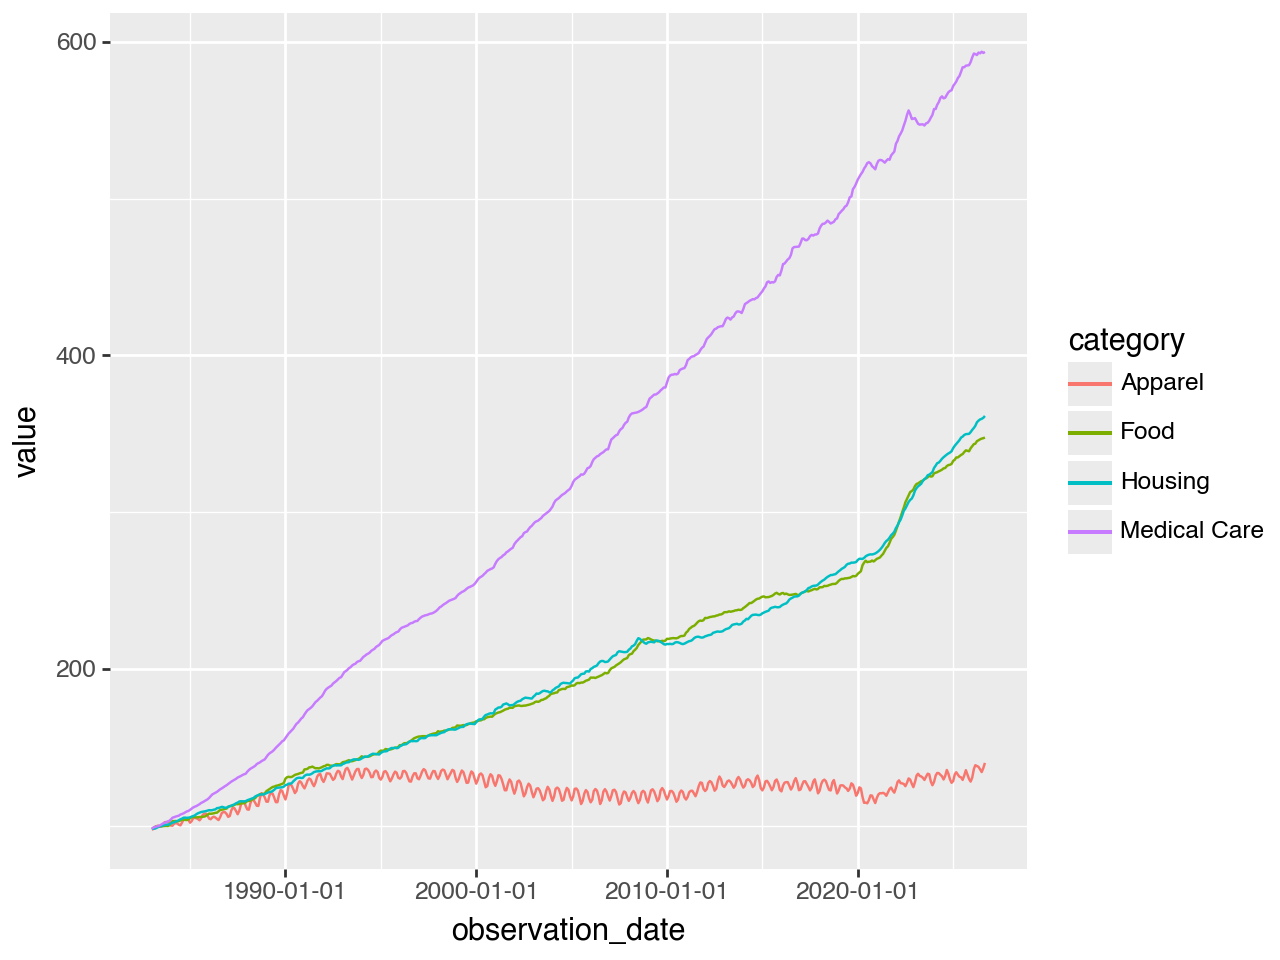

In [6]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'))
)

## First edits

When building out a chart, I usually start by adjusting the x and y axes. For this dataset, my x-axis is a date, so I can use the `scale_x_date()` function to customize the date labels.

The y-axis is simpler, I'm using a tupple to pass (min, max) values for the limits. Breaks looks more complicated, but I'm just passing a series of numbers to the `breaks` argument, I could have easily written `breaks=[100, 200, 300, 400, 500, 600]`; however, the function makes the code more future proof if my data frame is updated with new values.

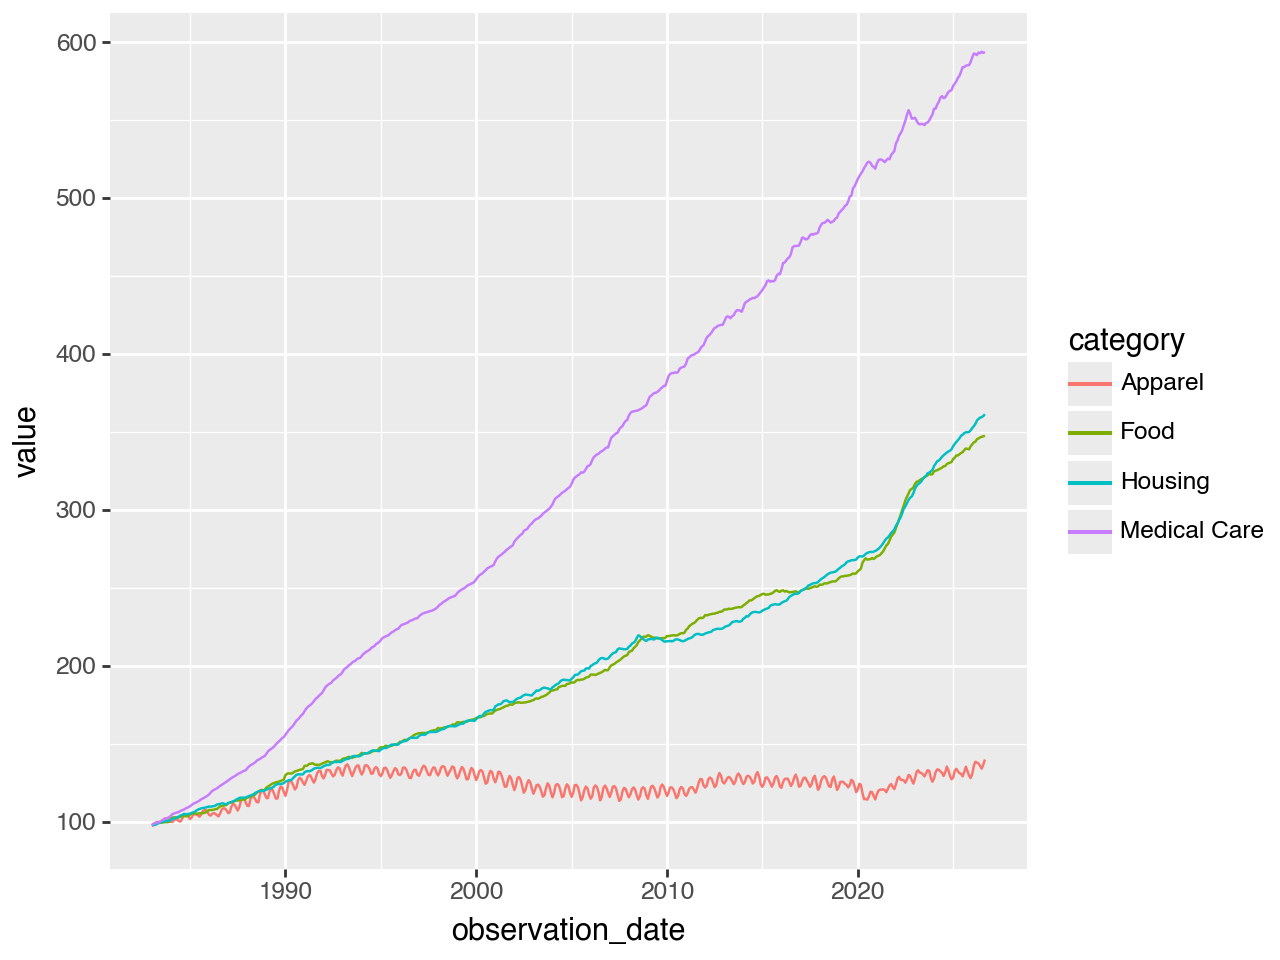

In [7]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'))
    + scale_x_date(date_labels='%Y')
    + scale_y_continuous(
        limits=(95, long_df['value'].max()), 
        breaks=pl.linear_space(100, 600, 6, eager=True)
    )
)

## Moving the legend to the inside (top) of the chart

This is done using the chart's `theme()` layer. Each element should be self explanatory. 

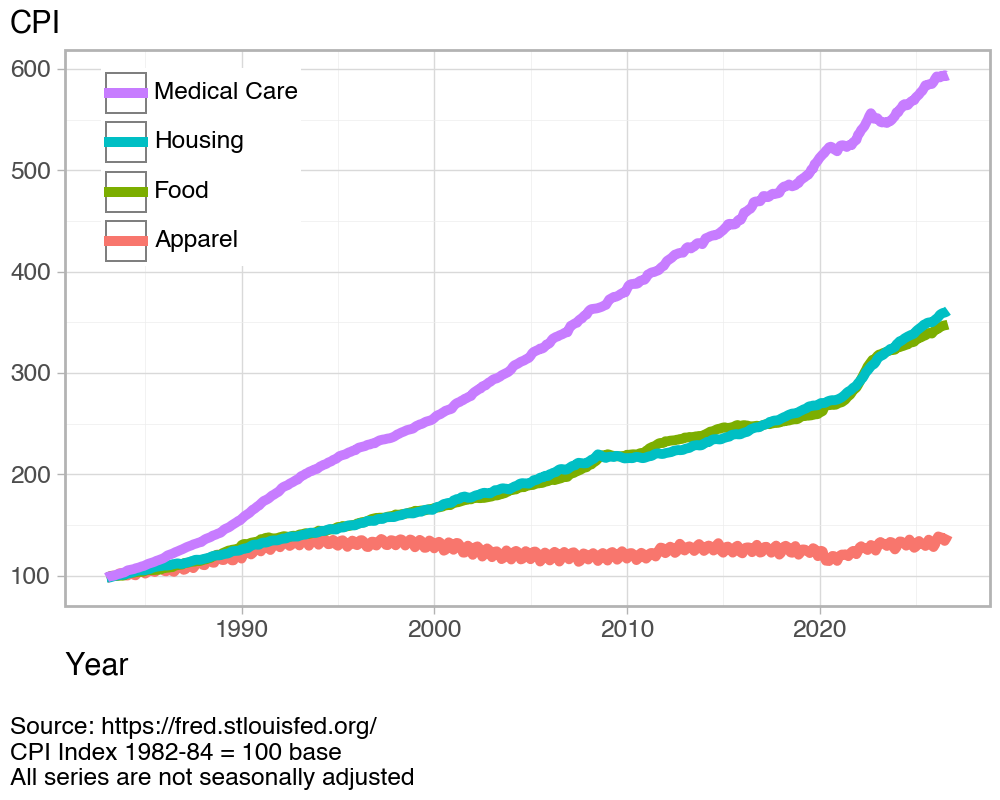

In [8]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'), size=2)
    + labs(
        subtitle = 'CPI',
        x = 'Year',
        caption = ('Source: https://fred.stlouisfed.org/ \n'
                   'CPI Index 1982-84 = 100 base \n'
                   'All series are not seasonally adjusted')
    )
    + scale_x_date(date_labels='%Y')
    + scale_y_continuous(
        limits=(95, long_df['value'].max()), 
        breaks=pl.linear_space(100, 600, 6, eager=True)
    )
    + guides(color=guide_legend(reverse=True))
    + theme_light()
    + theme(
        figure_size=(5,4),
        plot_title_position='plot',
        legend_position='inside',
        legend_position_inside=(0.05, 0.95),
        legend_title=element_blank(),
        plot_caption=element_text(
            ha='left', 
            linespacing=1.2, 
            margin={'t':10}),
        plot_caption_position='plot',
        axis_title_x=element_text(ha='left'),
        axis_title_y=element_blank()
    )
)